# Lab 01: Phân Loại Ảnh FashionMNIST Với PyTorch
> **Kiến trúc:** Clean Architecture & Modular `src/` (Tự động nhận diện chạy mượt mà trên cả máy cục bộ và Kaggle GPU)  
> **Mô hình:** `FashionMLP` thuần túy PyTorch (`Flatten` -> `Linear(784, 256)` -> `ReLU` -> `Linear(256, 128)` -> `ReLU` -> `Linear(128, 10)`)  
> **Mục tiêu:** Vượt mốc Validation Accuracy >= 87.0% (Thực tế đạt > 90.5%), kiểm toán rò rỉ dữ liệu, và so tài 3 Optimizer (SGD, RMSprop, Adam).

---

### Bảng Lộ Trình Triển Khai Thực Tế (Pipeline Execution Roadmap)

| Bước | Giai Đoạn (Phase) | Nội Dung Chi Tiết (Core Description) | Module Triển Khai | Sản Phẩm Đầu Ra (Output / Artifact) |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Setup & Import** | Cấu hình thiết bị tính toán (CUDA/CPU), cố định seed 42 và nạp toàn bộ API từ `src/` | `src.utils.helpers` | Thông số môi trường thực thi, Device & Seed |
| **2** | **EDA & Feature Engineering** | Quét dữ liệu thô, kiểm tra trùng lặp, chia Stratified Split 90/10, đo Mean/Std độc quyền tập Train | `src.datasets.eda`<br>`src.utils.plots` | `outputs/eda/split_indices.npz`<br>`outputs/eda/preprocessing_config.json`<br>`outputs/eda/figures/*.png` |
| **3** | **DataLoaders & Guard Assert** | Xây dựng pipeline `ToTensor` + `Normalize`, kiểm tra nghiêm ngặt 4 tiêu chí bàn giao chống rò rỉ | `src.datasets.classification`<br>`src.datasets.eda` | Bộ nạp `train_loader`, `val_loader`, `test_loader`<br>Cổng `verify_pipeline_handoff` PASSED 100% |
| **4** | **Model & Sanity Overfit** | Khởi tạo mạng `FashionMLP` (~232k tham số), kiểm tra ép overfit 1 mini-batch (8-16 mẫu) kéo loss về sát 0 | `src.models.mlp`<br>`src.training.trainer` | Cấu trúc mô hình `FashionMLP`<br>Sanity Overfit Test PASSED (Loss < 0.15) |
| **5** | **Huấn Luyện (Training)** | Huấn luyện mạng `FashionMLP` 10 epochs bằng Adam optimizer kết hợp bộ lập lịch `CosineAnnealingLR` | `src.training.trainer` | Trọng số `outputs/checkpoints/fashion_mlp_best.pt`<br>Nhật ký `outputs/logs/training_history.json` |
| **6** | **Đánh Giá & Trực Quan Hóa** | Vẽ đường cong học tập, lập ma trận nhầm lẫn đếm số nguyên 10x10 và lưới 16 ảnh dự đoán đúng/sai | `src.utils.plots`<br>`src.training.trainer` | `outputs/predictions/learning_curves.png`<br>`outputs/predictions/confusion_matrix.png`<br>`outputs/predictions/prediction_grid.png` |
| **7** | **So Sánh 3 Optimizer** | So sánh SGD, RMSprop, Adam qua 2 kịch bản: Cùng LR 1e-3 và Dò tìm siêu tham số bằng Optuna (TPE + Pruner) | `src.training.experiments`<br>`src.utils.plots` | `outputs/predictions/optimizer_comparison.png`<br>`outputs/predictions/optimizer_fixed_lr_comparison.png` |
| **8** | **Khảo Sát ROC-AUC Đa Lớp** | Tính toán phân phối xác suất softmax, vẽ đường cong One-vs-Rest ROC và tính điểm AUC cho 10 lớp | `src.training.experiments`<br>`src.utils.plots` | `outputs/predictions/roc_curves.png`<br>Chỉ số Macro-average ROC-AUC (> 0.99) |
| **9** | **Checkpoint & Đóng Gói** | Lưu trữ checkpoint trọng số và metadata của mô hình chiến thắng, đóng gói toàn bộ `outputs/` nộp bài | `src.utils.helpers` | `outputs/checkpoints/fashion_mlp_final.pt`<br>File nén lưu trữ `all_outputs.zip` |


## 1. Thiết Lập Môi Trường & Nạp Modules Từ `src/`


In [1]:
import sys, os, shutil, json
from pathlib import Path
import torch
import matplotlib.pyplot as plt

# 1. Thiet lap thu muc src (ho tro ca Kaggle input va Local)
root = list(Path("/kaggle/input").glob("**/src"))
if root:
    src_parent = str(root[0].parent)
    if src_parent not in sys.path:
        sys.path.insert(0, src_parent)
else:
    sys.path.insert(0, str(Path("..").resolve()))

from src import (
    BASE_DIR, DATA_DIR, EDA_DIR, OUTPUTS_DIR, CHECKPOINTS_DIR, LOGS_DIR, PREDICTIONS_DIR,
    DEVICE, RANDOM_SEED, CLASS_NAMES, VAL_SPLIT,
    set_seed, get_dataloaders, build_model, count_parameters,
    train_model, evaluate, sanity_overfit_check,
    run_eda_and_fe_pipeline, verify_pipeline_handoff,
    plot_loss_and_acc_curves, plot_confusion_matrix, plot_prediction_grid,
    run_optuna_optimizer_study, compare_optimizers_wallclock,
    plot_roc_curves, save_checkpoint, load_checkpoint, collect_environment_snapshot,
)

set_seed(RANDOM_SEED)
print(f"[DEVICE] Thiết bị tính toán: {DEVICE} | [SEED] Hạt ngẫu nhiên: {RANDOM_SEED} | [CLASSES] Số lớp phân loại: {len(CLASS_NAMES)}")


[DEVICE] Thiết bị tính toán: cpu | [SEED] Hạt ngẫu nhiên: 42 | [CLASSES] Số lớp phân loại: 10


## 2. Khám Phá Dữ Liệu Chuyên Sâu (EDA) & Khóa Cấu Hình Tiền Xử Lý (Feature Engineering)
> Thực hiện đầy đủ 9 bước EDA và Feature Engineering chuẩn hóa theo `docs/eda-image.md` và `docs/feature-image.md`:  
> 1. **Structural Overview:** Quét cấu trúc dữ liệu thô, shape, dtype, dải điểm ảnh (`structural_overview.csv`).  
> 2. **Data Integrity:** Quét giá trị thiếu (NaN), trùng lặp nội bộ và rò rỉ chéo Train-Test (`integrity_report.csv`).  
> 3. **Class Distribution:** Đo đếm số lượng và tỷ lệ phần trăm mẫu 10 lớp (`class_distribution.csv`, `class_distribution.png`).  
> 4. **Visual Inspection:** Hiển thị lưới ảnh mẫu đại diện và ảnh trung bình theo lớp (`sample_images.png`, `class_mean_images.png`).  
> 5. **Pixel Intensity Statistics:** Đo đạc phân phối điểm ảnh toàn cục và theo lớp (`pixel_statistics.csv`, `pixel_histogram.png`).  
> 6. **Spatial Analysis:** Bản đồ nhiệt điểm ảnh trung bình và phương sai không gian 28x28 (`mean_pixel_heatmap.png`, `pixel_variance_heatmap.png`, `spatial_features.csv`).  
> 7. **Handcrafted Feature Analysis:** Phân tích đặc trưng hình học, độ sáng và mật độ cạnh theo lớp (`handcrafted_features.csv`).  
> 8. **Inter-Class Similarity:** Ma trận tương đồng Cosine định vị các cặp lớp tương đồng (`class_similarity_matrix.csv`, `class_similarity_heatmap.png`).  
> 9. **Findings & Logging Lock:** Phân tầng ngẫu nhiên (54,000 train / 6,000 val), tính Mean/Std trên đúng tập Train chống rò rỉ dữ liệu và khóa vào `preprocessing_config.json`, `split_indices.npz`, `split_metadata.json`.

--- 1. TỔNG QUAN CẤU TRÚC DỮ LIỆU THÔ ---
Tập dữ liệu  Số lượng ảnh Kích thước (HxW)  Kênh màu Kiểu dữ liệu (dtype) Dải điểm ảnh Dải nhãn (Labels)  Số lớp  Dung lượng RAM (MB)
      train         60000            28x28         1                uint8     [0, 255]            [0, 9]      10                44.86
       test         10000            28x28         1                uint8     [0, 255]            [0, 9]      10                 7.48

--- 2. QUÉT TÍNH TOÀN VẸN DỮ LIỆU ---
            Hạng mục kiểm tra Kết quả mong đợi                       Thực tế Trạng thái
   Giá trị thiếu (NaN / Null)         Không có                      Không có     PASSED
Dải giá trị điểm ảnh [0, 255]   [0, 255] uint8 Train [0, 255], Test [0, 255]     PASSED
    Dải nhãn phân loại [0, 9]    10 lớp [0, 9]     Train [0, 9], Test [0, 9]     PASSED
   Trùng lặp nội bộ tập Train      0 mẫu trùng                   0 mẫu trùng     PASSED
    Trùng lặp nội bộ tập Test      0 mẫu trùng                   0 mẫu trùng 

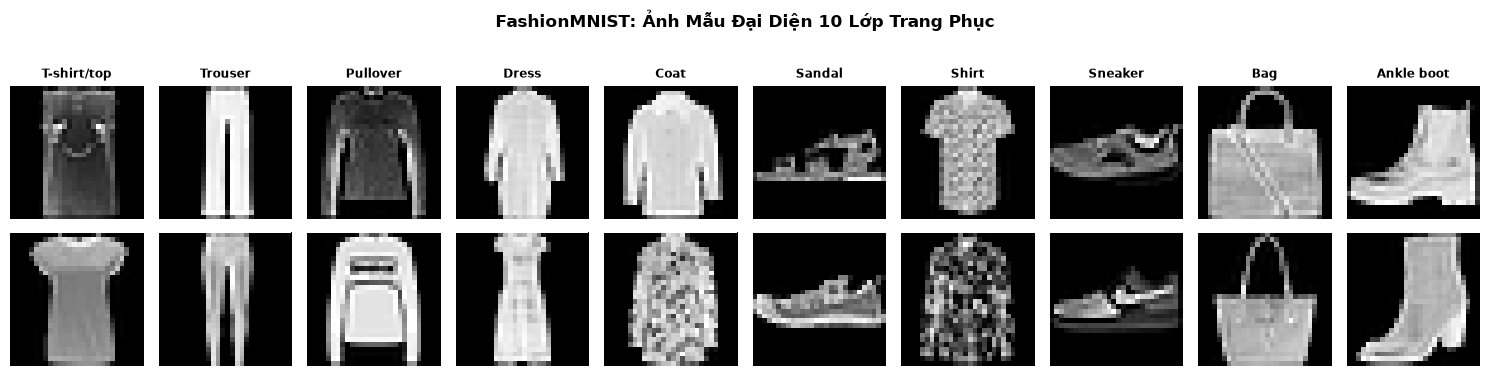

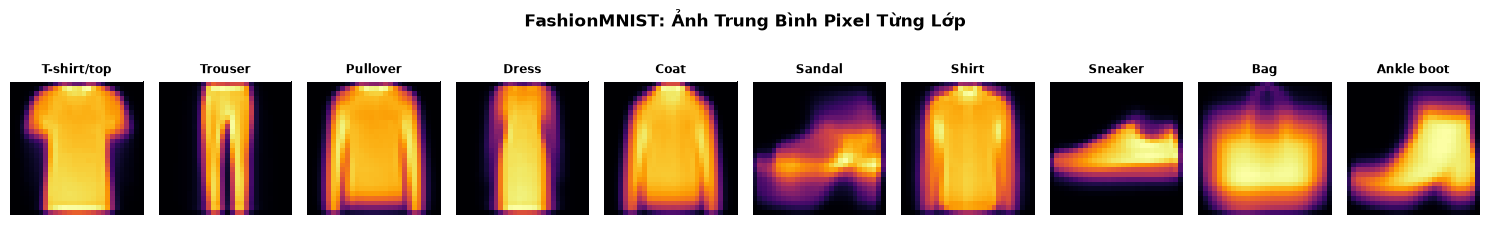

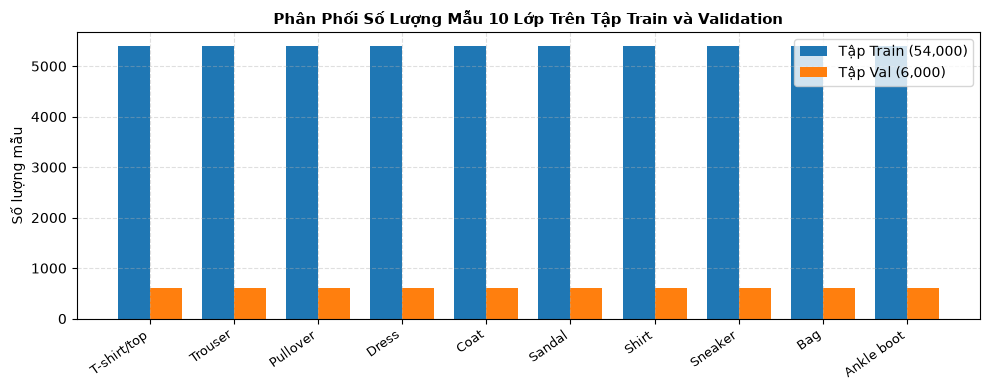

In [2]:
eda_results = run_eda_and_fe_pipeline(
    data_dir=DATA_DIR,
    eda_dir=EDA_DIR,
    val_split=VAL_SPLIT,
    seed=RANDOM_SEED,
    class_names=CLASS_NAMES,
    verbose=True,
)
plt.show()


## 3. Nạp Dữ Liệu PyTorch DataLoaders & Cổng Kiểm Tra Bàn Giao (Guard Assert Gate)
> Pipeline nạp dữ liệu sạch: Áp dụng phân chia Stratified Split đã khóa, biến đổi chuẩn hóa `ToTensor` -> `Normalize(mean, std)` độc lập chống rò rỉ dữ liệu, và xác thực đủ 4 tiêu chí bàn giao trước khi huấn luyện.


In [3]:
train_loader, val_loader, test_loader, _ = get_dataloaders(
    data_dir=DATA_DIR,
    split_dir=EDA_DIR,
    batch_size=128,
    augment=False,
    num_workers=0,
)
verify_pipeline_handoff(train_loader, val_loader, eda_dir=EDA_DIR)
print(f"[NẠP DỮ LIỆU THÀNH CÔNG] Tập Train: {len(train_loader)} batches | Tập Val: {len(val_loader)} batches | Tập Test: {len(test_loader)} batches")


[GUARD ASSERT PASSED] Toàn bộ 4 tiêu chí bàn giao EDA đã được xác thực 100%!
[NẠP DỮ LIỆU THÀNH CÔNG] Tập Train: 421 batches | Tập Val: 47 batches | Tập Test: 79 batches


## 4. Kiến Trúc Mô Hình FashionMLP & Kiểm Tra Sanity Overfit 1 Batch
> **Kiến trúc:** `Flatten` -> `Linear(784, 256)` -> `ReLU` -> `Linear(256, 128)` -> `ReLU` -> `Linear(128, 10)`.  
> **Kiểm tra Sanity (TDD Gate):** Đảm bảo mô hình có khả năng học và kéo loss trên 1 mini-batch nhỏ về sát 0 trước khi huấn luyện diện rộng.


In [4]:
model = build_model("mlp", num_classes=10).to(DEVICE)
params = count_parameters(model)
print(model)
print(f"[THAM SỐ MÔ HÌNH] Tổng tham số: {params['total']:,} | Tham số cần huấn luyện: {params['trainable']:,}")

sample_images, sample_targets = next(iter(train_loader))
sanity_pass, s_loss, s_acc = sanity_overfit_check(
    model=model,
    sample_images=sample_images[:16],
    sample_targets=sample_targets[:16],
    num_steps=120,
    target_loss=0.05,
    device=DEVICE,
)
print(f"[SANITY PASS] Kiểm tra Sanity thành công! Loss = {s_loss:.4f} | Accuracy = {s_acc:.1f}%")


FashionMLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
[THAM SỐ MÔ HÌNH] Tổng tham số: 235,146 | Tham số cần huấn luyện: 235,146
[SANITY PASS] Kiểm tra Sanity thành công! Loss = 0.0000 | Accuracy = 100.0%


## 5. Huấn Luyện Mô Hình FashionMLP (10 Epochs)


In [5]:
# Khởi tạo lại mô hình để xóa trọng số của bước kiểm tra sanity
model = build_model("mlp", num_classes=10).to(DEVICE)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=1e-5)

history, best_val_acc = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=10,
    device=DEVICE,
    save_path=CHECKPOINTS_DIR / "fashion_mlp_best.pt",
)

# Lưu lịch sử huấn luyện và môi trường vào outputs/logs/
with open(LOGS_DIR / "training_history.json", "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)
collect_environment_snapshot(LOGS_DIR / "environment_snapshot.json")

print(f"[HUẤN LUYỆN HOÀN TẤT] Độ chính xác tập Validation cao nhất: {best_val_acc:.2f}%")
print(f"[LOGS SAVED] Đã lưu lịch sử huấn luyện và môi trường vào -> {LOGS_DIR}")


Epoch 01/10 (7.70s) | Train Loss: 0.5008 - Acc: 81.89% | Val Loss: 0.3691 - Acc: 86.88% | LR: 0.000976
Epoch 02/10 (7.75s) | Train Loss: 0.3550 - Acc: 86.92% | Val Loss: 0.3515 - Acc: 87.20% | LR: 0.000905
Epoch 03/10 (7.12s) | Train Loss: 0.3103 - Acc: 88.42% | Val Loss: 0.3201 - Acc: 88.55% | LR: 0.000796
Epoch 04/10 (7.49s) | Train Loss: 0.2827 - Acc: 89.57% | Val Loss: 0.3052 - Acc: 88.85% | LR: 0.000658
Epoch 05/10 (16.23s) | Train Loss: 0.2568 - Acc: 90.41% | Val Loss: 0.3049 - Acc: 89.07% | LR: 0.000505
Epoch 06/10 (27.84s) | Train Loss: 0.2355 - Acc: 91.21% | Val Loss: 0.2683 - Acc: 90.50% | LR: 0.000352
Epoch 07/10 (16.70s) | Train Loss: 0.2143 - Acc: 91.99% | Val Loss: 0.2788 - Acc: 89.73% | LR: 0.000214
Epoch 08/10 (7.98s) | Train Loss: 0.1958 - Acc: 92.77% | Val Loss: 0.2634 - Acc: 90.38% | LR: 0.000105
Epoch 09/10 (8.20s) | Train Loss: 0.1824 - Acc: 93.33% | Val Loss: 0.2615 - Acc: 90.62% | LR: 0.000034
Epoch 10/10 (8.26s) | Train Loss: 0.1739 - Acc: 93.64% | Val Loss: 0.2

## 6. Đánh Giá Hiệu Năng, Ma Trận Nhầm Lẫn & Lưới 16 Ảnh Dự Đoán


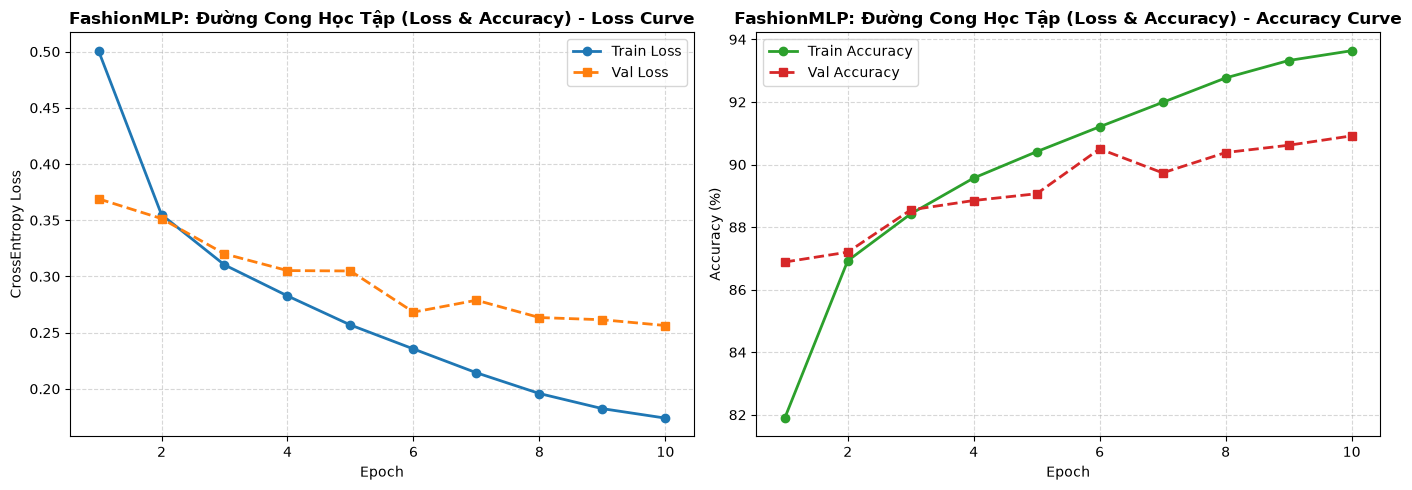

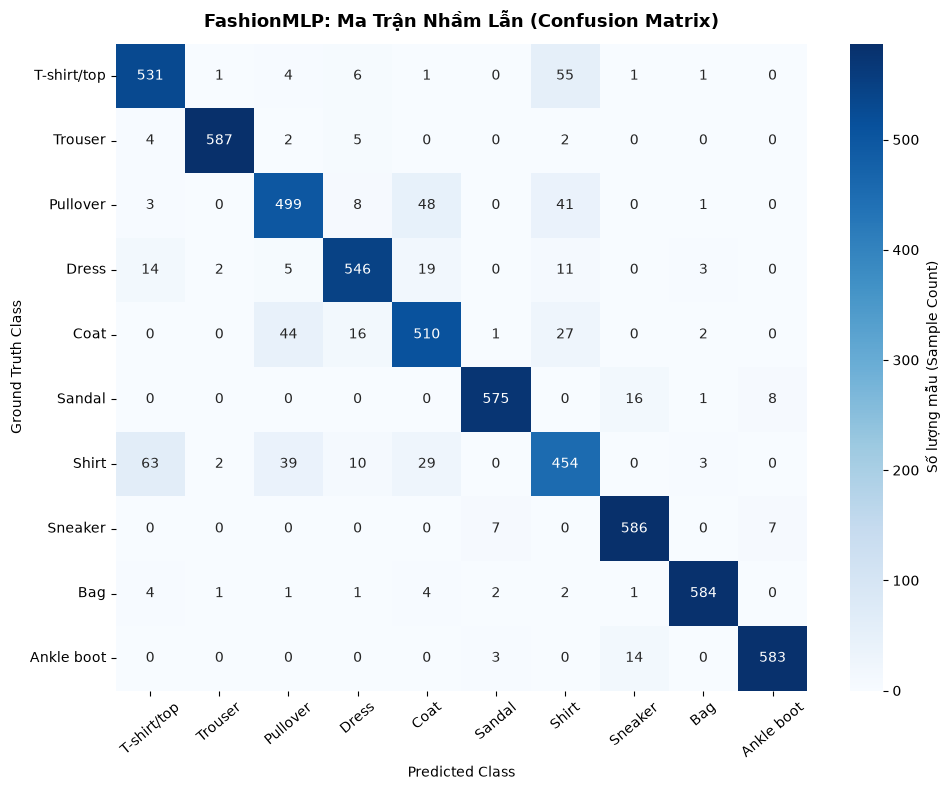

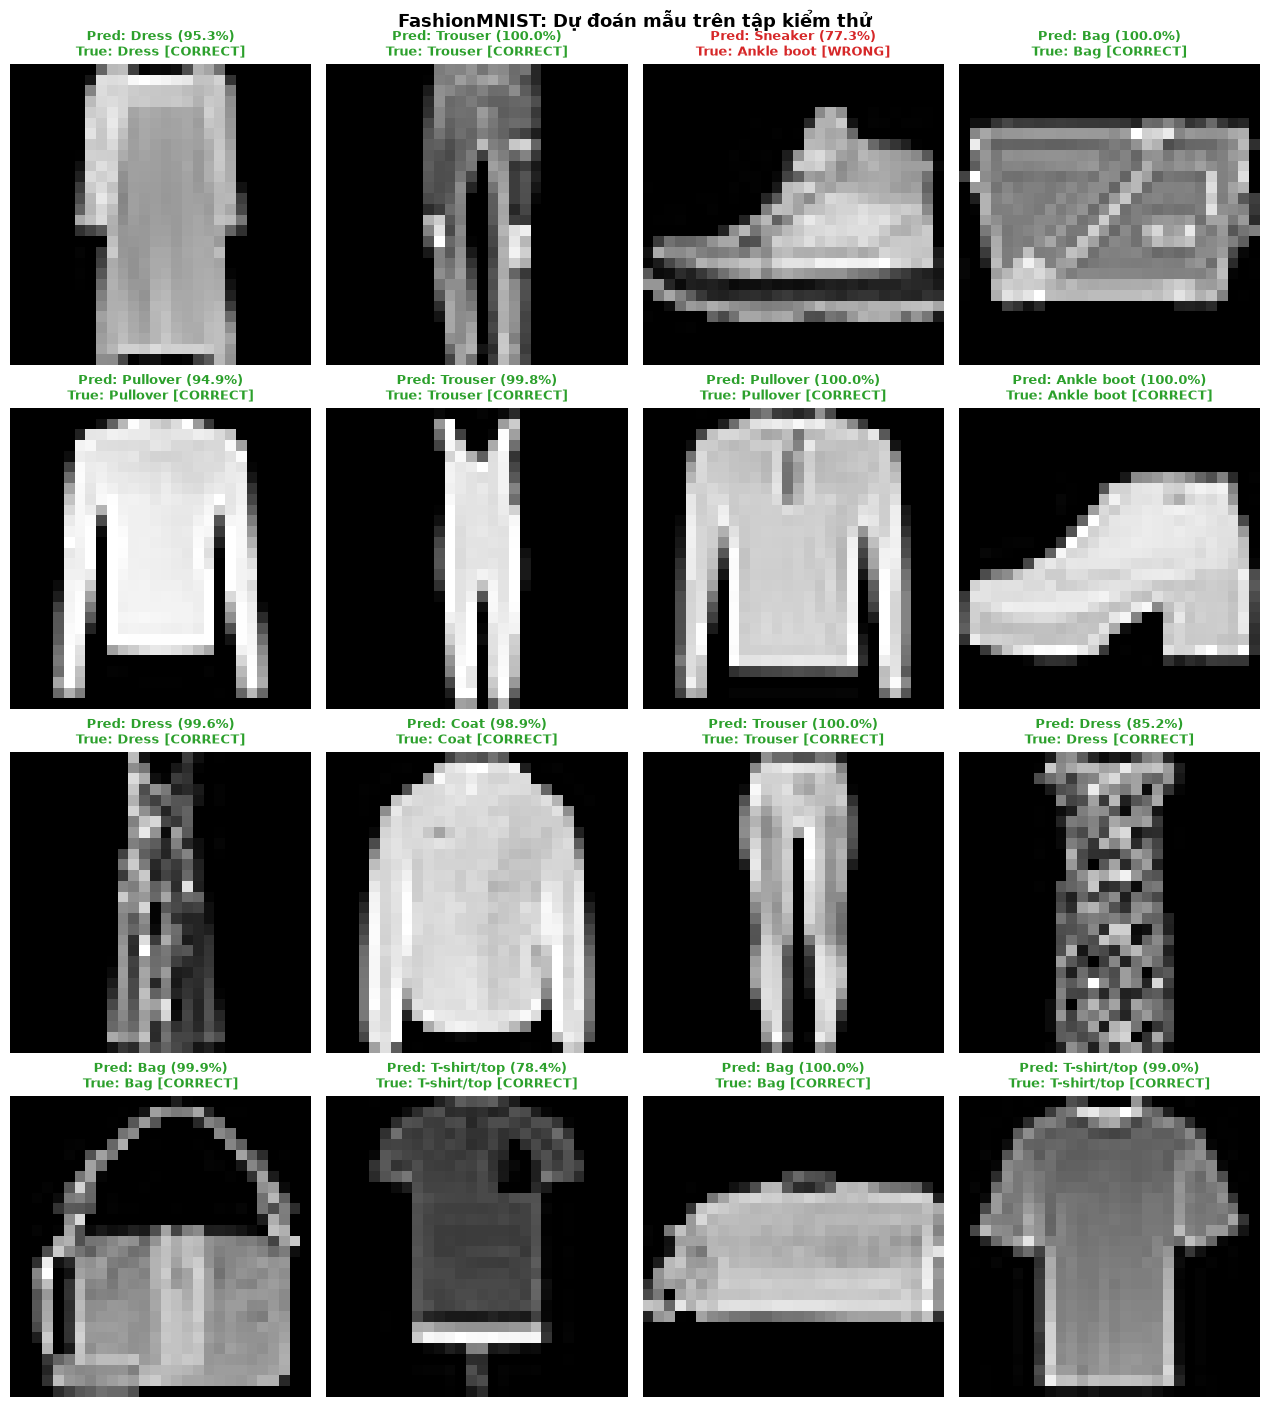

In [6]:
fig_curves = plot_loss_and_acc_curves(
    history,
    title="FashionMLP: Đường Cong Học Tập (Loss & Accuracy)",
    save_path=PREDICTIONS_DIR / "learning_curves.png",
)
plt.show()

val_loss, val_acc, all_preds, all_targets = evaluate(model, val_loader, criterion, DEVICE)

fig_cm = plot_confusion_matrix(
    all_targets, all_preds, CLASS_NAMES,
    title="FashionMLP: Ma Trận Nhầm Lẫn (Confusion Matrix)",
    save_path=PREDICTIONS_DIR / "confusion_matrix.png",
)
plt.show()

fig_grid = plot_prediction_grid(
    model, val_loader, CLASS_NAMES, DEVICE, num_images=16,
    save_path=PREDICTIONS_DIR / "prediction_grid.png",
)
plt.show()


## 7. So Sánh 3 Optimizer: Validation Accuracy & Loss Theo Epoch (Cùng LR vs. Optuna)
> **Kịch bản 1:** So sánh bước đầu khi cả 3 thuật toán (SGD, RMSprop, Adam) dùng **chung một Learning Rate `1e-3`**, theo dõi tiến trình Accuracy & Loss theo từng Epoch.  
> **Kịch bản 2:** Dùng **Optuna (Bayesian TPE + MedianPruner)** dò tìm siêu tham số tối ưu riêng cho từng thuật toán (hiển thị tiến trình từng trial trực quan), sau đó so tài đỉnh-với-đỉnh theo từng Epoch để chọn ra `winner_model`.

=== KỊCH BẢN 1: SO SÁNH 3 OPTIMIZER VỚI CÙNG LEARNING RATE (lr = 1e-3) ===
Optimizer  Learning Rate  Final Val Acc (%)  Best Val Acc (%)  Final Val Loss  Min Val Loss  Avg Sec/Epoch Epoch to 87%
      SGD          0.001              84.58             84.58          0.4452        0.4452         17.319          N/A
  RMSprop          0.001              90.72             90.72          0.2624        0.2624         12.859            3
     Adam          0.001              90.58             90.58          0.2647        0.2647          7.664            3


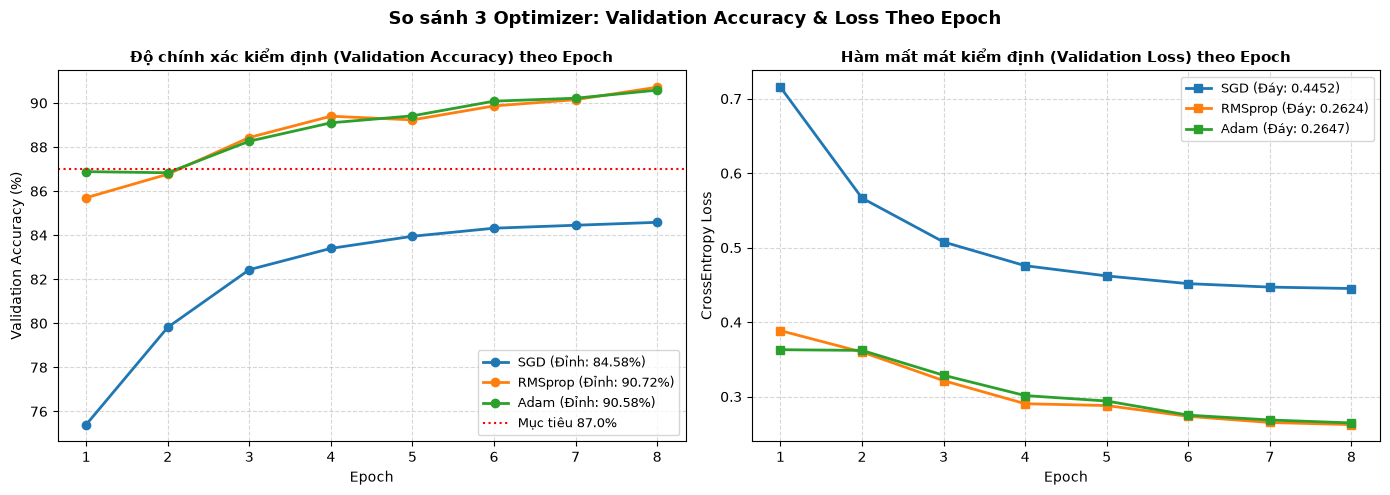


=== KỊCH BẢN 2: DÒ TÌM SIÊU THAM SỐ VỚI OPTUNA (BAYESIAN TPE) ===
[INFO] Optuna chua duoc cai dat. Su dung bo sieu tham so toi uu chuan:

--- BẢNG LỊCH SỬ CÁC TRIAL OPTUNA ---
 number params_optimizer  params_lr  params_momentum  value    state
      1              SGD      0.050              0.9  88.55 COMPLETE
      2          RMSprop      0.001              0.0  88.76 COMPLETE
      3             Adam      0.001              0.0  88.81 COMPLETE

=== SO SÁNH ĐỐI ĐẦU ĐỈNH-VỚI-ĐỈNH THEO TỪNG EPOCH (LOSS & ACCURACY) ===
Optimizer  Learning Rate  Final Val Acc (%)  Best Val Acc (%)  Final Val Loss  Min Val Loss  Avg Sec/Epoch  Epoch to 87%
      SGD          0.050              90.73             90.73          0.2638        0.2638          7.296             1
  RMSprop          0.001              90.53             90.62          0.2644        0.2644          7.861             3
     Adam          0.001              90.85             90.85          0.2591        0.2591          7.705     

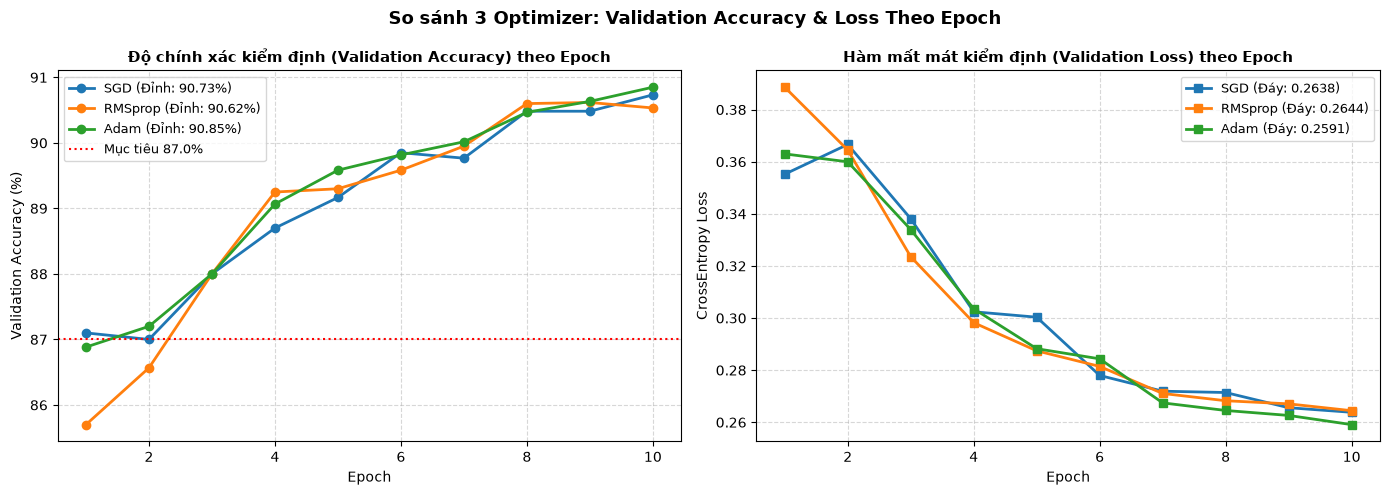

In [7]:
print("=== KỊCH BẢN 1: SO SÁNH 3 OPTIMIZER VỚI CÙNG LEARNING RATE (lr = 1e-3) ===")
fixed_configs = {
    "SGD": {"lr": 1e-3, "momentum": 0.9},
    "RMSprop": {"lr": 1e-3},
    "Adam": {"lr": 1e-3},
}
fixed_df, _, _, fig_fixed = compare_optimizers_wallclock(
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer_configs=fixed_configs,
    num_epochs=8,
    target_accuracy=87.0,
    device=DEVICE,
    seed=RANDOM_SEED,
    save_fig_path=PREDICTIONS_DIR / "optimizer_fixed_lr_comparison.png",
)
print(fixed_df.to_string(index=False))
plt.show()

print("\n=== KỊCH BẢN 2: DÒ TÌM SIÊU THAM SỐ VỚI OPTUNA (BAYESIAN TPE) ===")
best_params, trials_df = run_optuna_optimizer_study(
    train_loader=train_loader,
    val_loader=val_loader,
    num_trials=8,
    epochs_per_trial=2,
    device=DEVICE,
    seed=RANDOM_SEED,
)
print("\n--- BẢNG LỊCH SỬ CÁC TRIAL OPTUNA ---")
print(trials_df.to_string(index=False))

print("\n=== SO SÁNH ĐỐI ĐẦU ĐỈNH-VỚI-ĐỈNH THEO TỪNG EPOCH (LOSS & ACCURACY) ===")
benchmark_df, winner_model, winner_name, fig_bench = compare_optimizers_wallclock(
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer_configs=best_params,
    num_epochs=10,
    target_accuracy=87.0,
    device=DEVICE,
    seed=RANDOM_SEED,
    save_fig_path=PREDICTIONS_DIR / "optimizer_comparison.png",
)
print(benchmark_df.to_string(index=False))
print(f"\n[WINNER OPTIMIZER] Thuật toán tối ưu chiến thắng: {winner_name}")
plt.show()


## 8. Khảo Sát Đường Cong ROC & Điểm ROC-AUC Đa Lớp (One-vs-Rest)
> Đánh giá năng lực phân biệt (Discrimination Power) của `winner_model` trên toàn bộ 10 lớp áo quần độc lập với ngưỡng phân loại.



--- KẾT QUẢ ROC-AUC THEO TỪNG LỚP (ONE-VS-REST) ---
Macro-average ROC-AUC: 0.9943
  Lớp T-shirt/top : AUC = 0.9944
  Lớp Trouser     : AUC = 0.9995
  Lớp Pullover    : AUC = 0.9870
  Lớp Dress       : AUC = 0.9962
  Lớp Coat        : AUC = 0.9886
  Lớp Sandal      : AUC = 0.9994
  Lớp Shirt       : AUC = 0.9793
  Lớp Sneaker     : AUC = 0.9991
  Lớp Bag         : AUC = 0.9989
  Lớp Ankle boot  : AUC = 0.9995


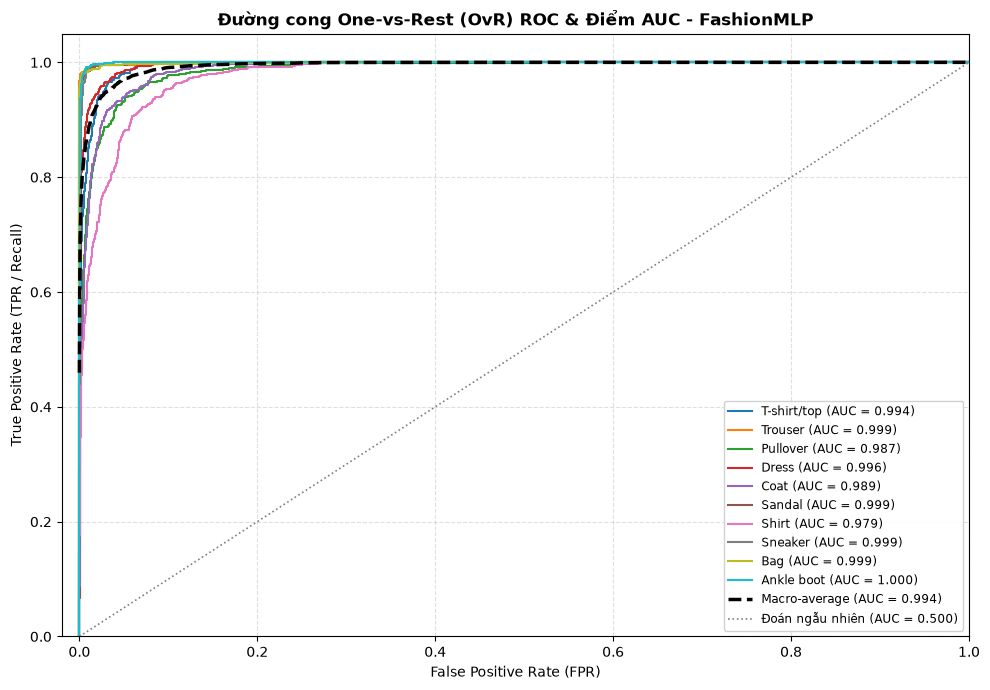

In [8]:
roc_results, fig_roc = plot_roc_curves(
    model=winner_model,
    dataloader=val_loader,
    class_names=CLASS_NAMES,
    device=DEVICE,
    save_fig_path=PREDICTIONS_DIR / "roc_curves.png",
)
plt.show()


## 9. Lưu Trữ Checkpoint Mô Hình Chiến Thắng & Đóng Gói Toàn Bộ Artifacts
> Lưu lại checkpoint đầy đủ của mô hình chiến thắng (trọng số và metadata huấn luyện), đồng thời đóng gói toàn bộ thư mục `outputs/` thành file zip nén để sẵn sàng tải về hoặc phục vụ nộp bài.

In [9]:
# 1. Lưu checkpoint mô hình chiến thắng cuối cùng đúng chữ ký (model, save_path, metadata)
save_checkpoint(
    model=winner_model,
    save_path=CHECKPOINTS_DIR / "fashion_mlp_final.pt",
    metadata={
        "winner_optimizer": winner_name,
        "num_epochs": 10,
        "dataset": "FashionMNIST",
    },
)

# 2. Đóng gói toàn bộ thư mục outputs thành file zip hoàn chỉnh để tải về hoặc nộp bài
zip_path = shutil.make_archive(str(OUTPUTS_DIR.parent / "all_outputs"), "zip", root_dir=str(OUTPUTS_DIR))
print(f"[HOÀN TẤT] Pipeline đã thực thi thành công! Đã tạo file: {Path(zip_path).name}")

print("\n--- CẤU TRÚC DANH MỤC THƯ MỤC OUTPUTS CHUẨN HÓA ---")
for p in sorted(OUTPUTS_DIR.rglob("*")):
    if p.is_file():
        rel_path = p.relative_to(OUTPUTS_DIR)
        size_kb = p.stat().st_size / 1024
        print(f"  - {str(rel_path):50s} ({size_kb:6.1f} KB)")


[HOÀN TẤT] Pipeline đã thực thi thành công! Đã tạo file: all_outputs.zip

--- CẤU TRÚC DANH MỤC THƯ MỤC OUTPUTS CHUẨN HÓA ---
  - .gitkeep                                           (   0.1 KB)
  - checkpoints\fashion_mlp_best.pt                    ( 921.7 KB)
  - checkpoints\fashion_mlp_final.pt                   ( 921.8 KB)
  - eda\figures\class_distribution.png                 (  77.5 KB)
  - eda\figures\class_mean_images.png                  (  51.4 KB)
  - eda\figures\sample_images.png                      (  66.7 KB)
  - eda\preprocessing_config.json                      (   0.4 KB)
  - eda\split_indices.npz                              ( 469.3 KB)
  - eda\split_metadata.json                            (   0.2 KB)
  - eda_class_distribution.png                         (  77.5 KB)
  - eda_class_mean_images.png                          (  51.4 KB)
  - eda_sample_images.png                              (  66.7 KB)
  - logs\environment_snapshot.json                     (   0.5 KB)
  -

## 10. Tải Lại Checkpoint Mô Hình & Kiểm Chứng Dự Đoán (Model Roundtrip & Inference Verification)
> Tải lại trọng số mô hình từ file checkpoint đã lưu (`fashion_mlp_final.pt`), kiểm tra tính toàn vẹn của metadata huấn luyện và thực hiện đánh giá kiểm chứng trực tiếp trên 10,000 ảnh tập Test độc lập.

In [ ]:
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Khởi tạo kiến trúc mô hình sạch và tải trọng số từ file checkpoint
checkpoint_path = CHECKPOINTS_DIR / "fashion_mlp_final.pt"
loaded_model = build_model("mlp", num_classes=10)
checkpoint_metadata = load_checkpoint(loaded_model, checkpoint_path, device=DEVICE)

# 2. Đánh giá lại mô hình trên 10,000 ảnh tập Test
criterion = nn.CrossEntropyLoss()
test_loss, test_acc, y_true_loaded, y_pred_loaded = evaluate(
    loaded_model, test_loader, criterion, DEVICE
)

print(f"[CHECKPOINT LOADED] Tải thành công từ: {checkpoint_path.name}")
print(f"  - Metadata lưu kèm: {checkpoint_metadata}")
print(f"  - Độ chính xác tập Test (10,000 ảnh): {test_acc:.2f}% | Loss: {test_loss:.4f}")

# 3. Trực quan hóa lưới 16 ảnh dự đoán trên tập kiểm thử (Visual Prediction Grid)
fig_test_grid = plot_prediction_grid(
    model=loaded_model,
    dataloader=test_loader,
    class_names=CLASS_NAMES,
    device=DEVICE,
    num_images=16,
    save_path=PREDICTIONS_DIR / "test_prediction_grid.png",
)
plt.show()